In [1]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

INTERP  = Path('/n/holylfs06/LABS/kempner_project_b/Lab/dendritic/adivm/dendritic-modeling/outputs/interpretability_results')
FIG_DIR = Path('figures'); FIG_DIR.mkdir(exist_ok=True)

# Point neuron (fc7 replaced by plain linear, fc8 kept) vs EINet at same N_E=4096
TAGS = {
    'point (fc7 linear)': 'fc7_point_ne4096',
    'EINet 2x2':          'fc7_2x2_ne4096',
    'EINet 3x3x3':        'fc7_3x3x3_ne4096',
}
COLORS = {
    'point (fc7 linear)': '#eda100',
    'EINet 2x2':          '#2a78d6',
    'EINet 3x3x3':        '#1baf7a',
}
N_E, N_CLASSES = 4096, 1000

def load(tag, name):
    return np.load(INTERP / tag / f'{name}.npy')

data = {}
for label, tag in TAGS.items():
    data[label] = {
        'W':        load(tag, 'fc8_weight_projection'),
        'pcm':      load(tag, 'per_class_mean_act'),
        'sel':      load(tag, 'selectivity_index'),
        'abl_delta':load(tag, 'ablation_acc_delta'),
    }
    s = data[label]['sel']
    print(f"{label}: sel mean={s.mean():.4f}  max={s.max():.4f}")

point (fc7 linear): sel mean=0.2656  max=1.0000
EINet 2x2: sel mean=0.0859  max=0.2891
EINet 3x3x3: sel mean=0.0789  max=0.2779


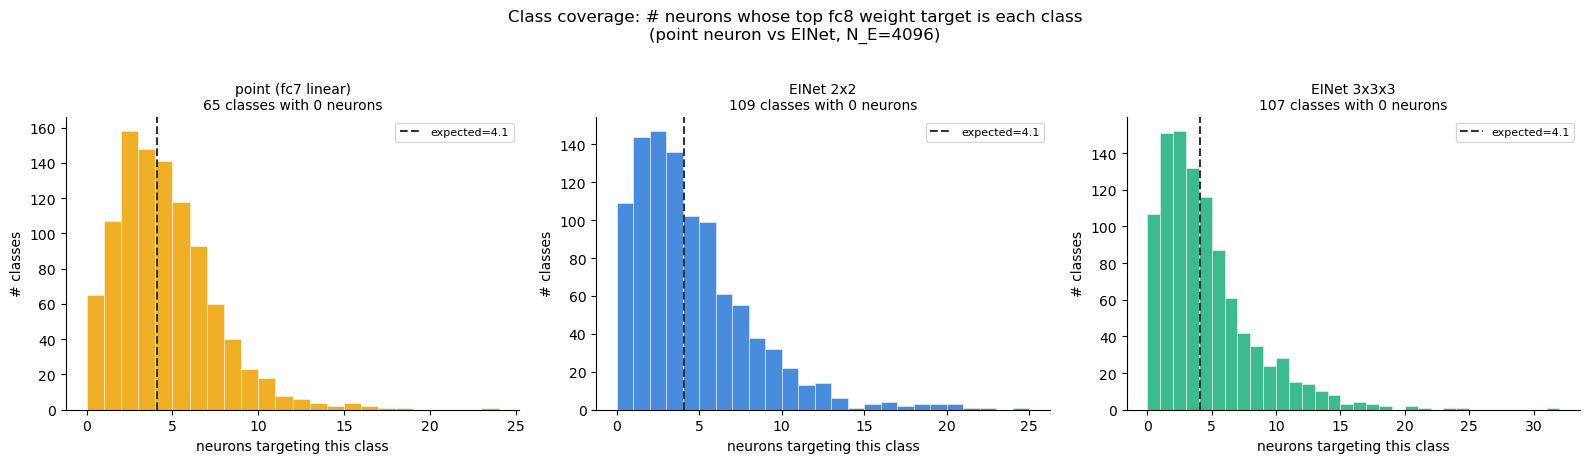

In [2]:
# ── Figure 1: Class coverage ─────────────────────────────────────────────────
# How many neurons point their strongest fc8 weight at each ImageNet class?
# Expected if uniform = 4096/1000 ≈ 4.1

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
expected = N_E / N_CLASSES

for ax, (label, d) in zip(axes, data.items()):
    top1   = d['W'].argmax(axis=1)
    counts = np.bincount(top1, minlength=N_CLASSES)

    ax.hist(counts, bins=range(0, counts.max()+2), color=COLORS[label],
            edgecolor='white', lw=0.4, alpha=0.85)
    ax.axvline(expected, color='#333', lw=1.5, ls='--', label=f'expected={expected:.1f}')
    ax.set_xlabel('neurons targeting this class', fontsize=10)
    ax.set_ylabel('# classes', fontsize=10)
    ax.set_title(f'{label}\n{(counts==0).sum()} classes with 0 neurons', fontsize=10)
    ax.legend(fontsize=8)
    ax.spines[['top','right']].set_visible(False)

plt.suptitle('Class coverage: # neurons whose top fc8 weight target is each class\n'
             '(point neuron vs EINet, N_E=4096)', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'baseline_fig1_class_coverage.pdf', bbox_inches='tight')
plt.show()

In [ ]:
# ── Figure 2: Lifetime sparseness distribution ───────────────────────────────
# How peaked is each neuron's response profile across 1000 classes?
# S≈0 = fires equally for all classes; S≈1 = fires for only one class
#
# Dead neurons excluded: those that never fire (S=0) AND whose ablation changes
# nothing (Σ|Δacc|=0). Same (0,0) filter as Figure 3, so both figures describe
# the same population. In the point model these are 65% of all neurons — left in,
# they pile into the S=0 bin and drag the reported mean toward 0.

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (label, d) in zip(axes, data.items()):
    sel  = d['sel']
    live = (sel > 0) | (np.abs(d['abl_delta']).sum(axis=1) > 0)
    n_dropped = (~live).sum()
    sel = sel[live]

    ax.hist(sel, bins=80, color=COLORS[label], edgecolor='none', alpha=0.85)
    ax.axvline(sel.mean(), color='#333', lw=1.2, ls='--',
               label=f'mean={sel.mean():.4f}')
    ax.set_xlabel('lifetime sparseness S', fontsize=10)
    ax.set_ylabel('# neurons', fontsize=10)
    ax.set_title(f'{label}   n={live.sum()}  ({n_dropped} dead dropped)', fontsize=10)
    ax.legend(fontsize=8)
    ax.spines[['top','right']].set_visible(False)
    print(f"{label}: dropped {n_dropped} at (0,0)  live n={live.sum()}  mean={sel.mean():.4f}")

plt.suptitle('Lifetime sparseness distribution (S=1: single class, S=0: uniform)\n'
             'point neuron vs EINet, N_E=4096 — dead neurons excluded', fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'baseline_fig2_sparseness.pdf', bbox_inches='tight')
plt.show()

point (fc7 linear): r=-0.759  mean_impact=1.5288  dropped 2658 at (0,0)
EINet 2x2: r=-0.537  mean_impact=2.4968  dropped 0 at (0,0)
EINet 3x3x3: r=-0.526  mean_impact=2.3908  dropped 0 at (0,0)


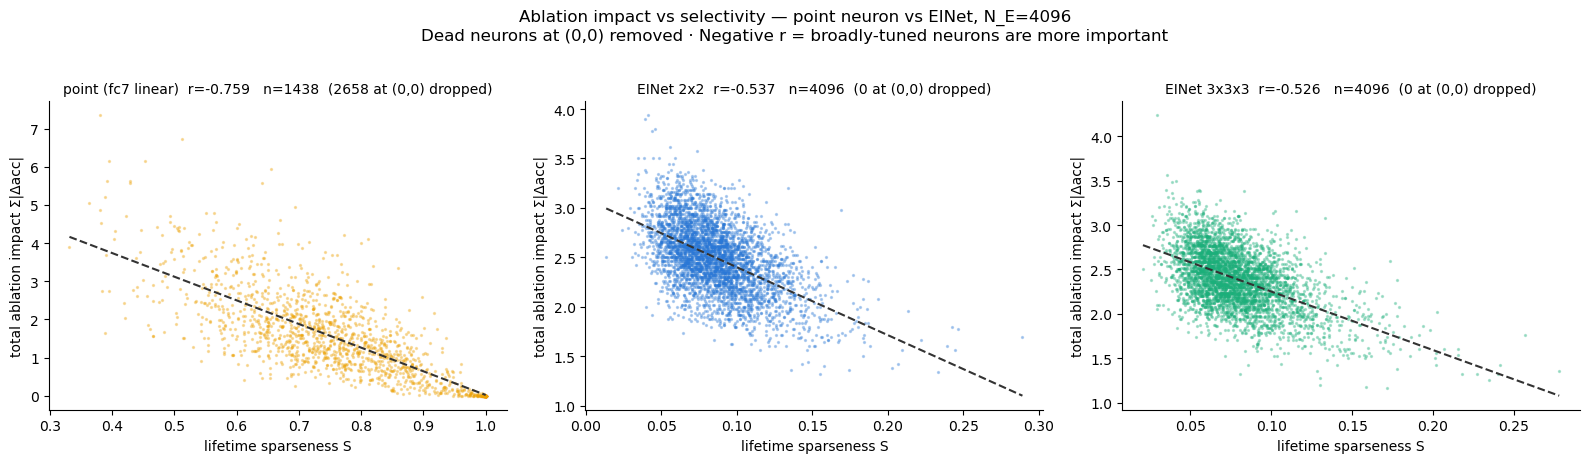

In [4]:
# ── Figure 3: Ablation impact (Σ|Δacc|) vs lifetime sparseness ──────────────
# X: lifetime sparseness S per neuron
# Y: total damage from silencing that neuron — sum of |acc change| across all 1000 classes
# If selective neurons matter more: should be positive correlation
#
# Points sitting exactly at (0,0) are dropped: neurons that never fire (S=0) AND
# whose ablation changes nothing (Σ|Δacc|=0). In the point model they are 65% of
# the population, and that degenerate point mass alone sets the sign of the fit.

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (label, d) in zip(axes, data.items()):
    sel          = d['sel']
    total_impact = np.abs(d['abl_delta']).sum(axis=1)

    live = (sel > 0) | (total_impact > 0)
    n_dropped = (~live).sum()
    sel, total_impact = sel[live], total_impact[live]

    ax.scatter(sel, total_impact, s=2, alpha=0.3, color=COLORS[label], rasterized=True)
    z  = np.polyfit(sel, total_impact, 1)
    xr = np.linspace(sel.min(), sel.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color='#333', lw=1.5, ls='--')
    r  = np.corrcoef(sel, total_impact)[0, 1]

    ax.set_xlabel('lifetime sparseness S', fontsize=10)
    ax.set_ylabel('total ablation impact Σ|Δacc|', fontsize=10)
    ax.set_title(f'{label}  r={r:.3f}   n={len(sel)}  ({n_dropped} at (0,0) dropped)', fontsize=10)
    ax.spines[['top','right']].set_visible(False)
    print(f"{label}: r={r:.3f}  mean_impact={total_impact.mean():.4f}  "
          f"dropped {n_dropped} at (0,0)")

plt.suptitle('Ablation impact vs selectivity — point neuron vs EINet, N_E=4096\n'
             'Dead neurons at (0,0) removed · Negative r = broadly-tuned neurons are more important',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'baseline_fig3_ablation_vs_sel.pdf', bbox_inches='tight')
plt.show()

point (fc7 linear): sel mean=0.2656  max=1.0000
EINet 2x2: sel mean=0.0859  max=0.2891
EINet 3x3x3: sel mean=0.0789  max=0.2779
point (fc7 linear): r=0.093  median net Δacc=-0.060  63.9% of neurons net-useful  dropped 2658
EINet 2x2: r=-0.012  median net Δacc=+0.020  44.0% of neurons net-useful  dropped 0
EINet 3x3x3: r=-0.020  median net Δacc=-0.020  55.6% of neurons net-useful  dropped 0


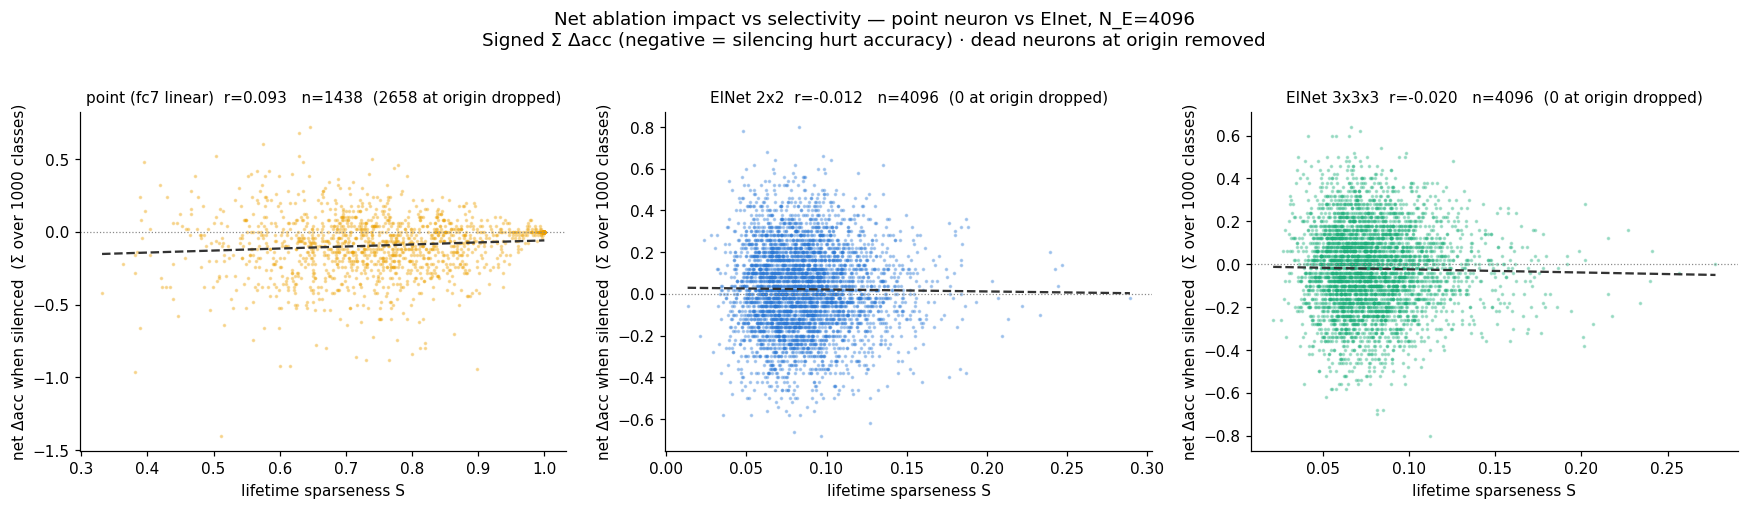

In [1]:
# ── Figure 3: Ablation impact (NET Δacc, signed) vs lifetime sparseness ──────
# X: lifetime sparseness S per neuron
# Y: NET accuracy change when that neuron is silenced, summed over all 1000 classes.
#    SIGNED, not |Δacc|. Convention: abl_delta = ablated_acc - baseline_acc, so
#      negative = silencing HURT accuracy = the neuron was doing useful work
#      positive = silencing HELPED = the neuron was net harmful
#
# Resolution note: ImageNet val has exactly 50 images per class, so every per-class
# Δacc is a multiple of 1/50 = 0.02. Summing over 1000 classes gives enough steps to
# plot continuously; single-class Δacc does not (it is 0/±0.02/±0.04 -- see fig v2).
#
# Dead neurons at the origin are dropped. The deadness test deliberately uses |Δacc|,
# not the net: a neuron that is +0.02 on one class and -0.02 on another nets to exactly
# zero but is NOT dead. Using the net here would silently discard live neurons.

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, (label, d) in zip(axes, data.items()):
    sel        = d['sel']
    net_impact = d['abl_delta'].sum(axis=1)             # signed, plotted
    abs_impact = np.abs(d['abl_delta']).sum(axis=1)     # deadness test only

    live = (sel > 0) | (abs_impact > 0)
    n_dropped = (~live).sum()
    sel, net_impact = sel[live], net_impact[live]

    ax.scatter(sel, net_impact, s=2, alpha=0.3, color=COLORS[label], rasterized=True)
    ax.axhline(0, color='#888', lw=0.8, ls=':')
    z  = np.polyfit(sel, net_impact, 1)
    xr = np.linspace(sel.min(), sel.max(), 100)
    ax.plot(xr, np.poly1d(z)(xr), color='#333', lw=1.5, ls='--')
    r  = np.corrcoef(sel, net_impact)[0, 1]

    ax.set_xlabel('lifetime sparseness S', fontsize=10)
    ax.set_ylabel('net Δacc when silenced  (Σ over 1000 classes)', fontsize=10)
    ax.set_title(f'{label}  r={r:.3f}   n={len(sel)}  ({n_dropped} at origin dropped)', fontsize=10)
    ax.spines[['top','right']].set_visible(False)
    print(f"{label}: r={r:.3f}  median net Δacc={np.median(net_impact):+.3f}  "
          f"{np.mean(net_impact < 0)*100:.1f}% of neurons net-useful  dropped {n_dropped}")

plt.suptitle('Net ablation impact vs selectivity — point neuron vs EInet, N_E=4096\n'
             'Signed Σ Δacc (negative = silencing hurt accuracy) · dead neurons at origin removed',
             fontsize=12, y=1.02)
plt.tight_layout()
plt.savefig(FIG_DIR / 'baseline_fig3_ablation_vs_sel_signed.pdf', bbox_inches='tight')
plt.show()